<a href="https://colab.research.google.com/github/minhimmaturity/ai-engineer/blob/master/03_thi_nghiem_sieu_tham_so.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Bài 3: Thí nghiệm với siêu tham số

**Buổi 3: Máy học hoạt động như thế nào?** · ⏱️ 30 phút

Sau bài này bạn sẽ:
- Thấy tận mắt ảnh hưởng của **tốc độ học** (slide 34–36)
- Tự làm thí nghiệm đổi **một** tham số và giải thích bằng trực giác (slide 40–43)
- Áp dụng vào ảnh thật trong thử thách **Fashion-MNIST**

**Hình ảnh cần nhớ (slide 17–18):** huấn luyện giống như đi **xuống núi trong sương mù**. Bạn chỉ cảm nhận được độ dốc dưới chân rồi bước một bước.

| Tham số | Trong câu chuyện xuống núi |
|---|---|
| **Tốc độ học** (learning rate, η) | Bước chân dài bao nhiêu? |
| **Kích thước lô** (batch size) | Hỏi đường bao nhiêu người trước khi bước? Hỏi nhiều thì chắc hướng hơn, nhưng mỗi bước lâu hơn |
| **Epoch** | Đi hết con đường bao nhiêu lượt? |

Chạy ô cài đặt bên dưới trước (`Shift + Enter`). Chỗ cần điền là dấu `____`.

In [1]:
#@title ⚙️ Ô cài đặt: bấm ▶ để chạy, không cần đọc code { display-mode: "form" }

import os, time, unicodedata, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from matplotlib.animation import FuncAnimation
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import HTML, display
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

MAU_TRAIN, MAU_VAL, MAU_3 = "#2a78d6", "#eb6834", "#1baf7a"
MAU_LOP0, MAU_LOP1 = "#e34948", "#2a78d6"
MUC_CHINH, MUC_PHU = "#0b0b0b", "#52514e"
NEN_HAI_LOP = LinearSegmentedColormap.from_list("nen", ["#f3b4b3", "#f0efec", "#a9c9f0"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "text.color": MUC_CHINH, "axes.labelcolor": MUC_PHU, "axes.titlecolor": MUC_CHINH,
    "xtick.color": MUC_PHU, "ytick.color": MUC_PHU, "lines.linewidth": 2, "font.size": 11,
    "axes.titlesize": 12, "legend.frameon": False, "figure.dpi": 100, "animation.embed_limit": 40,
})


def _bao_loi_than_thien(self, etype, value, tb, tb_offset=None):
    ten = getattr(value, "name", None) or str(value)
    if "____" in str(value):
        print("✏️  Ô này còn chỗ trống ____ chưa điền.\n"
              "    Hãy thay MỌI dấu ____ trong ô bằng giá trị theo gợi ý, rồi chạy lại ô.")
    else:
        print(f"🔎 Python chưa biết tên `{ten}`. Thường là do một trong ba lý do:\n"
              "    1. Một ô phía trên chưa chạy hoặc còn lỗi: hãy chạy lại các ô từ trên xuống.\n"
              "    2. Gõ sai tên (hoa/thường cũng tính là khác nhau).\n"
              '    3. Quên dấu ngoặc kép với chữ, ví dụ phải viết "relu" chứ không phải relu.')


try:
    get_ipython().set_custom_exc((NameError,), _bao_loi_than_thien)
except Exception:
    pass


def _dung(thong_bao):
    print("✅ " + thong_bao)


def _sai(thong_bao):
    print("❌ " + thong_bao)


def _luoi(X, n=90):
    bien_x = (X[:, 0].max() - X[:, 0].min()) * 0.12
    bien_y = (X[:, 1].max() - X[:, 1].min()) * 0.12
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - bien_x, X[:, 0].max() + bien_x, n),
                         np.linspace(X[:, 1].min() - bien_y, X[:, 1].max() + bien_y, n))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()].astype("float32")


def _xac_suat(model, luoi, hinh_dang):
    return np.array(model(luoi, training=False)).reshape(hinh_dang)


def _ve_nen(ax, xx, yy, zz):
    ax.contourf(xx, yy, zz, levels=np.linspace(0, 1, 41), cmap=NEN_HAI_LOP, vmin=0, vmax=1)
    if zz.min() < 0.5 < zz.max():
        ax.contour(xx, yy, zz, levels=[0.5], colors=MUC_CHINH, linewidths=2)


def _ve_diem(ax, X, y, nhan, rong=False):
    for lop, mau, dau in [(0, MAU_LOP0, "s"), (1, MAU_LOP1, "o")]:
        loc = np.asarray(y) == lop
        ten = f"{nhan[lop]}" + (" (validation)" if rong else "")
        if rong:
            ax.scatter(X[loc, 0], X[loc, 1], s=46, marker=dau, facecolors="#fcfcfb",
                       edgecolors=mau, linewidths=1.6, label=ten, zorder=3)
        else:
            ax.scatter(X[loc, 0], X[loc, 1], s=46, marker=dau, c=mau,
                       edgecolors="#fcfcfb", linewidths=0.8, label=ten, zorder=3)


class GhiLaiRanhGioi(tf.keras.callbacks.Callback):
    """Chụp lại đường phân chia của mô hình sau mỗi vài epoch."""

    def __init__(self, X, moi_bao_nhieu_epoch=2):
        super().__init__()
        self.moi = moi_bao_nhieu_epoch
        self.xx, self.yy, self.luoi = _luoi(X)
        self.cac_epoch, self.cac_khung = [], []

    def _chup(self, epoch):
        self.cac_epoch.append(epoch)
        self.cac_khung.append(_xac_suat(self.model, self.luoi, self.xx.shape))

    def on_train_begin(self, logs=None):
        self._chup(0)

    def on_epoch_end(self, epoch, logs=None):
        if (epoch + 1) % self.moi == 0:
            self._chup(epoch + 1)


def xem_qua_trinh_hoc(ghi_lai, lich_su, X_train, y_train, nhan=("Lớp 0", "Lớp 1"),
                      truc=("x1", "x2"), X_val=None, y_val=None):
    """Hoạt ảnh: bên trái là đường phân chia, bên phải là đường cong loss."""
    train, val = lich_su.history["loss"], lich_su.history["val_loss"]
    so_epoch = np.arange(1, len(train) + 1)
    fig, (ax_trai, ax_phai) = plt.subplots(1, 2, figsize=(10.5, 4.3), dpi=80)
    ax_phai.set_xlim(0, len(train))
    ax_phai.set_ylim(0, max(max(train), max(val)) * 1.08)
    ax_phai.set_xlabel("Epoch (số lần học hết dữ liệu)")
    ax_phai.set_ylabel("Hàm mất mát (loss)")
    duong_train, = ax_phai.plot([], [], color=MAU_TRAIN, label="Train (bài tập)")
    duong_val, = ax_phai.plot([], [], color=MAU_VAL, label="Validation (thi thử)")
    con_tro = ax_phai.axvline(0, color=MUC_PHU, linestyle="--", linewidth=1)
    ax_phai.legend(loc="upper right")
    ax_phai.set_title("Sai số theo thời gian")

    def ve_khung(i):
        epoch = ghi_lai.cac_epoch[i]
        ax_trai.clear()
        _ve_nen(ax_trai, ghi_lai.xx, ghi_lai.yy, ghi_lai.cac_khung[i])
        _ve_diem(ax_trai, X_train, y_train, nhan)
        if X_val is not None:
            _ve_diem(ax_trai, X_val, y_val, nhan, rong=True)
        ax_trai.set_xlim(ghi_lai.xx.min(), ghi_lai.xx.max())
        ax_trai.set_ylim(ghi_lai.yy.min(), ghi_lai.yy.max())
        ax_trai.set_xlabel(truc[0])
        ax_trai.set_ylabel(truc[1])
        ax_trai.grid(False)
        ax_trai.set_title(f"Đường phân chia sau epoch {epoch}")
        ax_trai.legend(loc="best", fontsize=8, frameon=True, framealpha=0.85, edgecolor="none")
        duong_train.set_data(so_epoch[:epoch], train[:epoch])
        duong_val.set_data(so_epoch[:epoch], val[:epoch])
        con_tro.set_xdata([epoch, epoch])

    ve_khung(0)
    fig.tight_layout()
    hoat_anh = FuncAnimation(fig, ve_khung, frames=len(ghi_lai.cac_khung), interval=180)
    html = hoat_anh.to_jshtml(default_mode="once")
    plt.close(fig)
    return HTML(html)


def ve_duong_cong(lich_su, tieu_de=""):
    """Vẽ 2 biểu đồ: loss và accuracy của train + validation."""
    fig, cac_truc = plt.subplots(1, 2, figsize=(10.5, 3.8))
    for ax, khoa, nhan_y in zip(cac_truc, ["loss", "accuracy"], ["Hàm mất mát (loss)", "Độ chính xác (accuracy)"]):
        for ten, tien_to, mau in [("Train", "", MAU_TRAIN), ("Validation", "val_", MAU_VAL)]:
            du_lieu = lich_su.history[tien_to + khoa]
            ax.plot(range(1, len(du_lieu) + 1), du_lieu, color=mau, label=ten)
        ax.set_xlabel("Epoch")
        ax.set_ylabel(nhan_y)
        ax.legend()
    if tieu_de:
        fig.suptitle(tieu_de)
    fig.tight_layout()
    plt.show()

from matplotlib.colors import LogNorm

_DU_LIEU = train_test_split(*make_moons(n_samples=300, noise=0.2, random_state=42), test_size=0.3, random_state=42)
X_train, X_val, y_train, y_val = _DU_LIEU
_MAU_SERIES = [MAU_TRAIN, MAU_VAL, MAU_3, "#6250d6"]
_NUI = LinearSegmentedColormap.from_list("nui", ["#104281", "#3987e5", "#9ec5f4", "#e6f0fc"])


def xuong_nui(cac_learning_rate, so_buoc=30):
    """Mô phỏng Gradient Descent W <- W - lr * gradient trên một thung lũng 2 chiều đơn giản."""
    goc = np.deg2rad(30)
    R = np.array([[np.cos(goc), -np.sin(goc)], [np.sin(goc), np.cos(goc)]])
    H = R @ np.diag([0.4, 2.0]) @ R.T
    J = lambda w: 0.5 * np.einsum("...i,ij,...j->...", w, H, w)
    gioi_han = 5
    aa, bb = np.meshgrid(np.linspace(-gioi_han, gioi_han, 200), np.linspace(-gioi_han, gioi_han, 200))
    zz = J(np.stack([aa, bb], axis=-1))
    so_cot = len(cac_learning_rate)
    fig, truc = plt.subplots(2, so_cot, figsize=(3.9 * so_cot, 6.6), squeeze=False,
                             gridspec_kw={"height_ratios": [1.5, 1]})
    for cot, lr in enumerate(cac_learning_rate):
        w = np.array([-4.0, 2.5])
        duong, sai_so = [w.copy()], [float(J(w))]
        for _ in range(so_buoc):
            w = w - lr * (H @ w)             # đúng công thức trên slide 34
            duong.append(w.copy())
            sai_so.append(float(J(w)))
        duong = np.array(duong)
        ngoai_khung = np.where(np.abs(duong).max(axis=1) > gioi_han)[0]
        duong_ve = duong[: ngoai_khung[0] + 1] if len(ngoai_khung) else duong
        ax = truc[0, cot]
        ax.contourf(aa, bb, zz, levels=np.geomspace(0.02, zz.max(), 14), cmap=_NUI, norm=LogNorm(), extend="min")
        ax.plot(duong_ve[:, 0], duong_ve[:, 1], color="#fcfcfb", linewidth=3, zorder=3)
        ax.plot(duong_ve[:, 0], duong_ve[:, 1], color=MAU_VAL, marker="o", markersize=4, linewidth=1.6, zorder=4)
        ax.scatter(*duong[0], s=80, c=MAU_LOP0, edgecolors="#fcfcfb", linewidths=1.5, zorder=5)
        ax.annotate("Bắt đầu", duong[0], xytext=(-24, 10), textcoords="offset points", color=MUC_CHINH, fontsize=10, zorder=6)
        ax.scatter(0, 0, s=110, marker="*", c="#fcfcfb", edgecolors=MUC_CHINH, zorder=5)
        ax.set_xlim(-gioi_han, gioi_han)
        ax.set_ylim(-gioi_han, gioi_han)
        ax.set_aspect("equal")
        ax.grid(False)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("w1")
        ax.set_ylabel("w2")
        if sai_so[-1] > sai_so[0]:
            nhan_xet = "Phân kỳ: càng đi càng xa"
        elif lr * 2.0 >= 1.9:
            nhan_xet = "Nhảy qua lại, không tới đáy"
        elif sai_so[-1] > 0.01 * sai_so[0]:
            nhan_xet = "Đúng hướng nhưng chưa tới đáy"
        else:
            nhan_xet = "Hội tụ về đáy"
        ax.set_title(f"learning rate = {lr}\n{nhan_xet}")
        ax2 = truc[1, cot]
        ax2.plot(sai_so, color=MAU_TRAIN)
        ax2.set_yscale("log")
        ax2.set_ylim(1e-6, 1e4)
        ax2.set_xlabel("Số bước")
        ax2.set_ylabel("Loss (thang log)")
    fig.tight_layout()
    plt.show()


def huan_luyen_thu(learning_rate=0.1, batch_size=16, epochs=40):
    """Huấn luyện mạng 1 lớp ẩn 16 nơ-ron bằng SGD. Dữ liệu và trọng số ban đầu luôn giống nhau."""
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(2,)),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=float(learning_rate)),
                  loss="binary_crossentropy", metrics=["accuracy"])
    bat_dau = time.time()
    lich_su = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size, verbose=0)
    lich_su.thoi_gian = time.time() - bat_dau
    lich_su.so_buoc_moi_epoch = int(np.ceil(len(X_train) / batch_size))
    return lich_su


def so_sanh_thi_nghiem(ket_qua):
    """ket_qua: từ điển {tên thí nghiệm: lịch sử huấn luyện}"""
    fig, cac_truc = plt.subplots(1, 2, figsize=(11, 4))
    bang = []
    for (ten, lich_su), mau in zip(ket_qua.items(), _MAU_SERIES):
        val_loss = np.nan_to_num(lich_su.history["val_loss"], nan=np.inf, posinf=np.inf)
        epoch = range(1, len(val_loss) + 1)
        cac_truc[0].plot(epoch, val_loss, color=mau, label=ten)
        cac_truc[1].plot(epoch, lich_su.history["val_accuracy"], color=mau, label=ten)
        bang.append({
            "Thí nghiệm": ten,
            "Val loss cuối": round(float(lich_su.history["val_loss"][-1]), 2),
            "Val accuracy cuối": round(float(lich_su.history["val_accuracy"][-1]), 2),
            "Cập nhật trọng số mỗi epoch": lich_su.so_buoc_moi_epoch,
            "Thời gian chạy (giây)": round(lich_su.thoi_gian, 1),
        })
    cao_nhat = max(float(np.nanmax(l.history["val_loss"])) for l in ket_qua.values())
    cac_truc[0].set_ylim(0, min(3, cao_nhat * 1.1) if np.isfinite(cao_nhat) else 3)
    cac_truc[0].set_ylabel("Val loss (thấp hơn là tốt hơn)")
    cac_truc[1].set_ylim(0, 1.02)
    cac_truc[1].set_ylabel("Val accuracy (cao hơn là tốt hơn)")
    for ax in cac_truc:
        ax.set_xlabel("Epoch")
    fig.tight_layout(rect=(0, 0, 1, 0.92))
    fig.legend(*cac_truc[0].get_legend_handles_labels(), loc="upper center", ncol=len(ket_qua))
    plt.show()
    display(pd.DataFrame(bang).set_index("Thí nghiệm"))


def thi_nghiem(ten_tham_so, cac_gia_tri):
    if ten_tham_so not in ("learning_rate", "batch_size"):
        _sai('ten_tham_so cần là "learning_rate" hoặc "batch_size".')
        return None
    if len(set(cac_gia_tri)) < 2:
        _sai("Hãy chọn ít nhất 2 giá trị khác nhau để có cái so sánh.")
        return None
    if ten_tham_so == "batch_size" and any(int(g) != g or g < 1 for g in cac_gia_tri):
        _sai("batch_size phải là số nguyên từ 1 trở lên.")
        return None
    if ten_tham_so == "learning_rate" and any(g <= 0 for g in cac_gia_tri):
        _sai("learning_rate phải lớn hơn 0.")
        return None
    ket_qua = {f"{ten_tham_so} = {g}": huan_luyen_thu(**{ten_tham_so: g}) for g in cac_gia_tri}
    so_sanh_thi_nghiem(ket_qua)
    _dung("Thí nghiệm đã chạy xong. Các tham số khác được giữ nguyên, nên khác biệt đến từ đúng tham số bạn đổi.")
    return ket_qua


TEN_DO_VAT = ["Áo thun", "Quần dài", "Áo len", "Váy đầm", "Áo khoác",
              "Dép xăng-đan", "Áo sơ mi", "Giày thể thao", "Túi xách", "Giày cổ cao"]
_nhat_ky = []
_mo_hinh_cac_lan = {}
SO_LUOT_TOI_DA = 5


def tai_fashion_mnist():
    """Lấy 3.000 ảnh để mỗi lần huấn luyện chỉ mất vài giây."""
    (anh, nhan), _ = tf.keras.datasets.fashion_mnist.load_data()
    chon = np.random.default_rng(42).permutation(len(anh))[:3000]
    anh, nhan = anh[chon].astype("float32") / 255.0, nhan[chon]
    return anh[:2400], anh[2400:], nhan[:2400], nhan[2400:]


def xem_anh(anh, nhan, so_anh=12):
    fig, cac_truc = plt.subplots(2, so_anh // 2, figsize=(so_anh * 0.95, 4.1))
    for ax, i in zip(cac_truc.ravel(), range(so_anh)):
        ax.imshow(anh[i], cmap="Greys")
        ax.set_title(TEN_DO_VAT[nhan[i]], fontsize=10)
        ax.axis("off")
    fig.tight_layout()
    plt.show()


def bat_dau_lai():
    _nhat_ky.clear()
    _mo_hinh_cac_lan.clear()
    print("Đã xóa nhật ký. Bạn có lại 5 lượt.")


def thu_mot_lan(X_anh, y_anh, X_anh_val, y_anh_val, learning_rate, so_noron, epochs, batch_size, dropout):
    if len(_nhat_ky) >= SO_LUOT_TOI_DA:
        print(f"⛔ Bạn đã dùng hết {SO_LUOT_TOI_DA} lượt. Chạy bat_dau_lai() nếu muốn chơi lại từ đầu.")
        return
    if epochs > 60 or so_noron > 1024:
        print("⛔ Để kịp giờ, hãy giữ epochs tối đa 60 và so_noron tối đa 1024. Lượt này chưa bị tính.")
        return
    tf.keras.utils.set_random_seed(42)
    lop = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten(),
           tf.keras.layers.Dense(so_noron, activation="relu")]
    if dropout > 0:
        lop.append(tf.keras.layers.Dropout(rate=dropout))
    lop.append(tf.keras.layers.Dense(10, activation="softmax"))
    model = tf.keras.Sequential(lop)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(learning_rate)),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    bat_dau = time.time()
    h = model.fit(X_anh, y_anh, validation_data=(X_anh_val, y_anh_val),
                  epochs=epochs, batch_size=batch_size, verbose=0).history
    lan = len(_nhat_ky) + 1
    _mo_hinh_cac_lan[lan] = model
    _nhat_ky.append({"Lượt": lan, "learning_rate": learning_rate, "so_noron": so_noron, "epochs": epochs,
                     "batch_size": batch_size, "dropout": dropout,
                     "Train accuracy": round(h["accuracy"][-1], 3), "Val accuracy": round(h["val_accuracy"][-1], 3),
                     "Giây": round(time.time() - bat_dau, 1)})
    bang = pd.DataFrame(_nhat_ky).set_index("Lượt")
    tot_nhat = bang["Val accuracy"].idxmax()
    hien_thi = bang.copy()
    hien_thi["Tốt nhất"] = ["🏆" if lan_i == tot_nhat else "" for lan_i in bang.index]
    display(hien_thi)
    print(f"🏆 Tốt nhất đến giờ: lượt {tot_nhat}, val accuracy = {bang['Val accuracy'].max():.1%}"
          f" · Còn lại {SO_LUOT_TOI_DA - len(_nhat_ky)} lượt")


def xem_du_doan(X_anh_val, y_anh_val, so_anh=12):
    if not _nhat_ky:
        print("Bạn cần chạy ít nhất một lượt trước.")
        return
    tot_nhat = pd.DataFrame(_nhat_ky).set_index("Lượt")["Val accuracy"].idxmax()
    du_doan = np.argmax(np.array(_mo_hinh_cac_lan[tot_nhat](X_anh_val[:400], training=False)), axis=1)
    dung = np.where(du_doan == y_anh_val[:400])[0][:so_anh // 2]
    sai = np.where(du_doan != y_anh_val[:400])[0][:so_anh // 2]
    fig, cac_truc = plt.subplots(2, so_anh // 2, figsize=(so_anh * 1.05, 4.6))
    for hang, chi_so, tieu_de in [(0, dung, "ĐÚNG"), (1, sai, "SAI")]:
        for ax, i in zip(cac_truc[hang], chi_so):
            ax.imshow(X_anh_val[i], cmap="Greys")
            ten = f"{tieu_de}: {TEN_DO_VAT[du_doan[i]]}"
            if hang == 1:
                ten += f"\n(thật: {TEN_DO_VAT[y_anh_val[i]]})"
            ax.set_title(ten, fontsize=9)
            ax.axis("off")
    fig.tight_layout()
    plt.show()


print("✅ Cài đặt xong! TensorFlow phiên bản", tf.__version__)

✅ Cài đặt xong! TensorFlow phiên bản 2.21.0


---
# 🔍 Phần A: Xem mẫu về tốc độ học (8 phút)

## A1. 🎬 Xuống núi với ba độ dài bước chân

Nhắc lại công thức cập nhật ở **slide 34**:

$$W \leftarrow W - \eta \frac{\partial J(W)}{\partial W}$$

`xuong_nui` mô phỏng đúng công thức này trên một thung lũng đơn giản. Hình trên nhìn từ trên xuống: màu càng đậm càng sâu, ⭐ là đáy thung lũng. Hình dưới là loss qua từng bước.

🤔 **Dự đoán:** với bước `1.05`, người đi sẽ tới đáy nhanh hơn hay xảy ra chuyện gì khác?

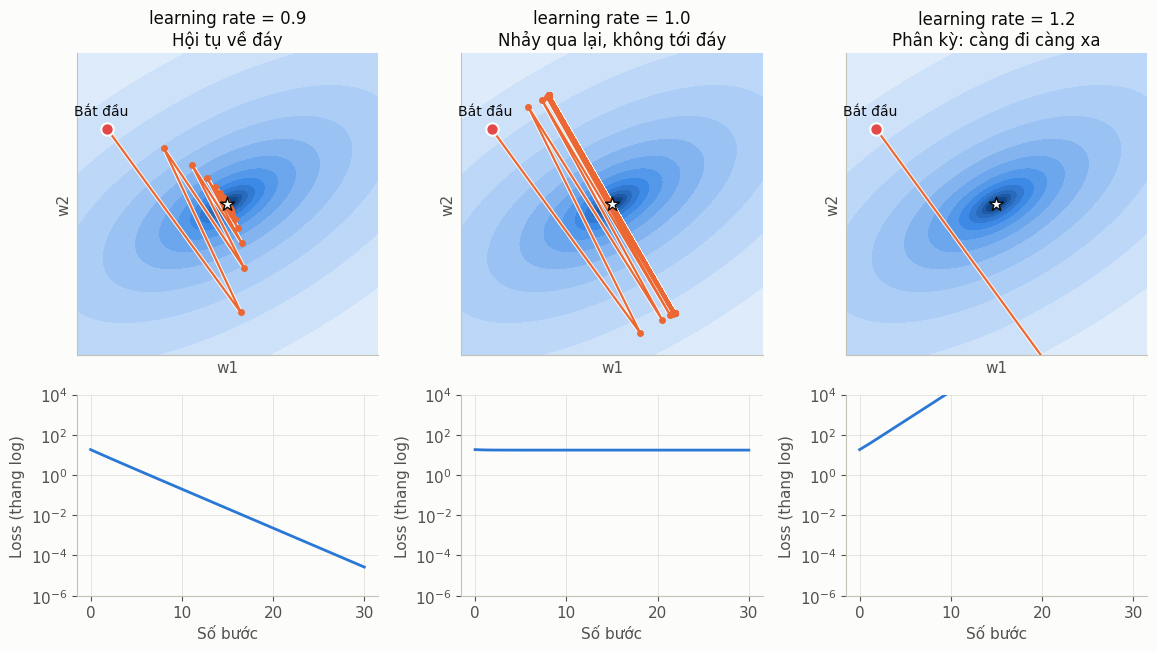

In [2]:
xuong_nui([0.9, 1.0, 1.2])

So sánh với **slide 35**: bước nhỏ thì hội tụ chậm, bước vừa thì tới đáy gọn, bước quá lớn thì **nhảy qua đáy** và có thể **phân kỳ**.

🎯 **Thử nhanh:** sửa các số trong ngoặc vuông ở ô trên rồi chạy lại. Bạn tìm được ngưỡng mà từ đó người đi bắt đầu phân kỳ không? *(Thử quanh khoảng 0.9 đến 1.1.)*

## A2. Trên một mô hình thật

Bây giờ đổi sang mạng nơ-ron thật trên dữ liệu trăng khuyết. Ta dùng **SGD** vì nó bám sát công thức trên. Hàm `huan_luyen_thu` đã viết sẵn phần tạo mô hình giống Bài 1, bạn chỉ cần đưa tham số vào:

| Tham số | Mặc định | Ý nghĩa |
|---|---|---|
| `learning_rate` | `0.1` | Độ dài bước chân |
| `batch_size` | `16` | Bao nhiêu điểm thì cập nhật trọng số một lần |
| `epochs` | `40` | Số lần học hết dữ liệu |

> 📌 Mức tốc độ học "lớn" hay "nhỏ" **tùy từng mô hình và thuật toán**. `20` chỉ để thấy rõ hiện tượng trên bài toán nhỏ này, không phải giá trị nên dùng trong thực tế. Slide 39 ví dụ `0.01` cho SGD và `0.001` cho Adam.

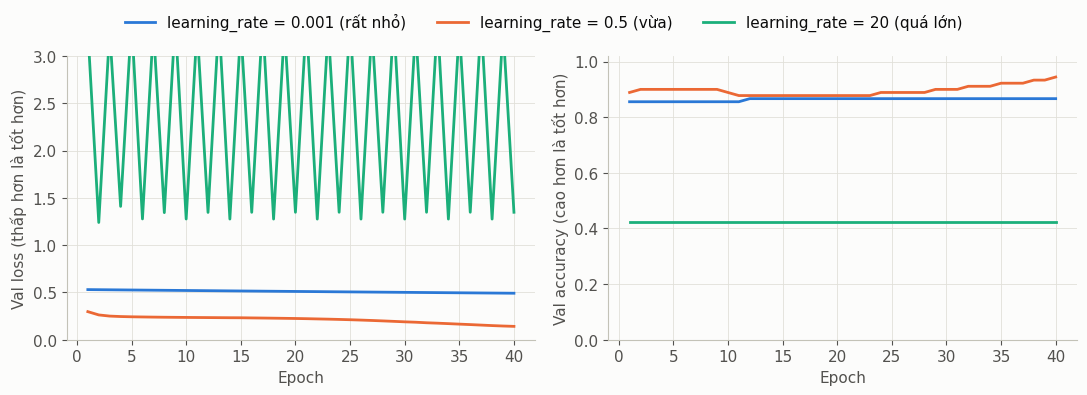

,Val loss cuối,Val accuracy cuối,Cập nhật trọng số mỗi epoch,Thời gian chạy (giây)
Thí nghiệm,,,,
learning_rate = 0.001 (rất nhỏ),0.49,0.87,14,6.5
learning_rate = 0.5 (vừa),0.14,0.94,14,5.0
learning_rate = 20 (quá lớn),1.35,0.42,14,7.2


In [3]:
ket_qua_lr = {
    "learning_rate = 0.001 (rất nhỏ)": huan_luyen_thu(learning_rate=0.001),
    "learning_rate = 0.5 (vừa)": huan_luyen_thu(learning_rate=0.5),
    "learning_rate = 20 (quá lớn)": huan_luyen_thu(learning_rate=20),
}

so_sanh_thi_nghiem(ket_qua_lr)

### Đọc kết quả

- **Rất nhỏ:** val loss gần như nằm ngang, 40 epoch vẫn chưa đủ. Bước chân bé nên chưa kịp xuống núi.
- **Vừa:** val loss giảm đều và thấp nhất, val accuracy cao nhất.
- **Quá lớn:** val loss nhảy lên xuống dữ dội, có đoạn vượt khỏi khung hình, val accuracy thấp hơn hẳn. Bước quá dài nên cứ vượt qua đáy, mô hình gần như không học được.

> Nếu bảng hiện `nan`, nghĩa là các con số đã lớn tới mức "vỡ" khi tính toán. Đó là dấu hiệu tốc độ học quá lớn.

---
# ✏️ Phần B: Thí nghiệm của bạn (12 phút)

Quy tắc của nhà khoa học: **mỗi lần chỉ đổi một thứ**, còn lại giữ nguyên.

## B1. Chọn tham số và dự đoán

| Lựa chọn | Nên thử | Liên quan |
|---|---|---|
| `"batch_size"` | `1`, `32`, `210` (toàn bộ tập train) | Slide 40–43 |
| `"learning_rate"` | Các giá trị bạn chọn, ví dụ `0.01`, `0.1`, `1` | Slide 35 |

🤔 **Dự đoán trước khi chạy** (bấm đúp để ghi vào đây):
#*dự đoán (32,0.1) sẽ cho giá trị val loss khá thấp, chạy vừa*
> Tôi chọn tham số 32 và 0.1 Tôi đoán giá trị (210, 0.01) sẽ cho val loss thấp nhất, và giá trị (210, 1) sẽ chạy lâu nhất.

## B2. ✏️ Chạy thí nghiệm

Điền tên tham số (có dấu ngoặc kép) và 3 giá trị muốn so sánh.

<details><summary>💡 Bấm để xem ví dụ</summary>

```python
ten_tham_so = "batch_size"
gia_tri_1 = 1
gia_tri_2 = 32
gia_tri_3 = 210
```
</details>

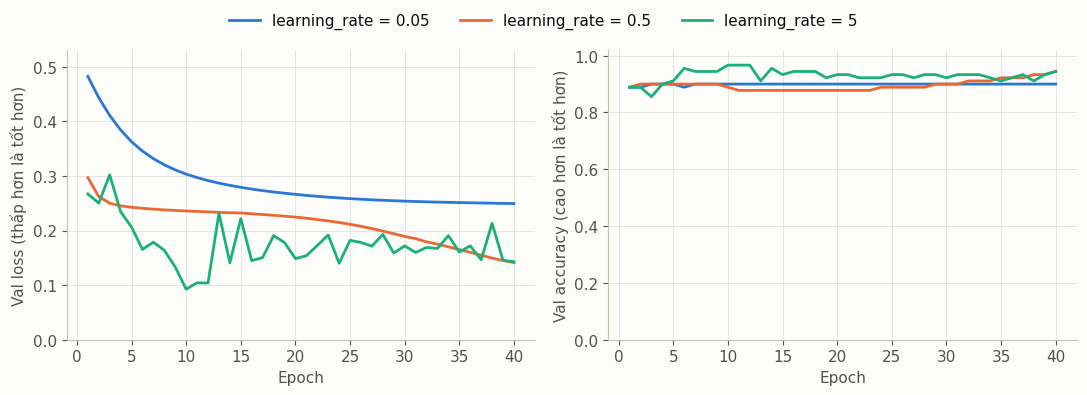

,Val loss cuối,Val accuracy cuối,Cập nhật trọng số mỗi epoch,Thời gian chạy (giây)
Thí nghiệm,,,,
learning_rate = 0.05,0.25,0.90,14,5.4
learning_rate = 0.5,0.14,0.94,14,6.4
learning_rate = 5,0.14,0.94,14,5.0


✅ Thí nghiệm đã chạy xong. Các tham số khác được giữ nguyên, nên khác biệt đến từ đúng tham số bạn đổi.


In [4]:
ten_tham_so = "learning_rate"   # ✏️ "batch_size" hoặc "learning_rate"
gia_tri_1 = 0.05             # ✏️ giá trị thứ nhất
gia_tri_2 = 0.5            # ✏️ giá trị thứ hai
gia_tri_3 = 5            # ✏️ giá trị thứ ba

ket_qua_cua_toi = thi_nghiem(ten_tham_so, [gia_tri_1, gia_tri_2, gia_tri_3])

## B3. 💬 Giải thích bằng trực giác

Nhìn biểu đồ và bảng, rồi bấm đúp vào ô này để hoàn thành:

> **Tôi đã đổi** learning rate **từ** 0.01 **thành** 1
>
> **Tôi thấy** đường val đi xuống nhanh hơn nhưng ổn định cũng sớm hơn
>
> **Giống như người xuống núi,** đường val của tôi trông giống nhất với đường của bước vừa
>
> **Dự đoán ban đầu của tôi** sai ở chỗ tôi cho rằng học càng chậm càng kỹ sẽ giúp loss càng thấp, còn thời gian chạy thì ở cả 3 bước chuyển là 0.01, 0.1 và 1 thì không quá chênh lệch và cũng không có quy luật về thời gian chạy này

<details><summary>💡 Bấm để xem cách nghĩ nếu bạn chọn batch_size</summary>

Hãy nhìn cột **"Cập nhật trọng số mỗi epoch"** trong bảng:

- `batch_size = 1`: mỗi epoch bước **210 lần**, nhưng mỗi bước chỉ hỏi đường một người nên hướng đi nhiễu (slide 41). Đi được nhiều bước nên xuống sâu, nhưng tốn thời gian nhất.
- `batch_size = 210`: mỗi epoch chỉ bước **1 lần**. Hướng đi chắc chắn nhất (slide 40), nhưng trong cùng 40 epoch thì chỉ có 40 bước, nên xuống được ít.
- `batch_size = 32`: dung hòa: hướng khá chắc, số bước đủ nhiều, chạy nhanh. Đây là ý tưởng của mini-batch (slide 42–43).

Lưu ý: kết luận này là cho cùng **số epoch**. Nếu tăng số epoch hoặc đổi tốc độ học, thứ tự có thể khác.
</details>

<details><summary>💡 Bấm để xem cách nghĩ nếu bạn chọn learning_rate</summary>

So với hình `xuong_nui` ở trên: đường val của bạn giống trường hợp bước nhỏ, vừa hay quá lớn? Thử tìm giá trị vừa giảm nhanh vừa không dao động.
</details>

---
# 🏆 Phần C: Thử thách Fashion-MNIST (10 phút)

Từ các điểm trên mặt phẳng, ta chuyển sang **ảnh thật**: nhận diện 10 loại quần áo, giày dép. Cách làm vẫn **y hệt**, giống bài toán mèo và chó ở slide 8–9.

Ta chỉ lấy 3.000 ảnh để chạy nhanh, nên bạn sẽ thấy quá khớp khá rõ.

Lần đầu chạy, Colab cần tải dữ liệu trong vài giây.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Ảnh để học: (2400, 28, 28) (số ảnh, cao, rộng)
Ảnh thi thử: (600, 28, 28)


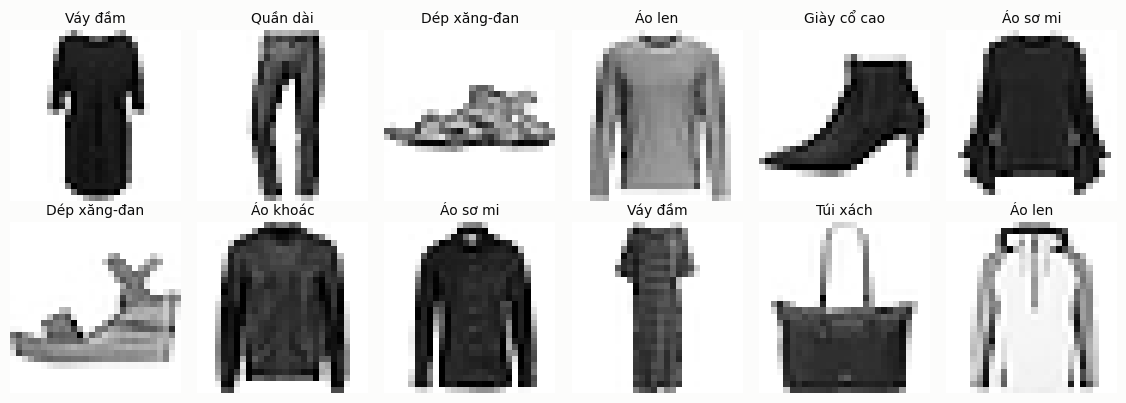

In [5]:
X_anh, X_anh_val, y_anh, y_anh_val = tai_fashion_mnist()

print("Ảnh để học:", X_anh.shape, "(số ảnh, cao, rộng)")
print("Ảnh thi thử:", X_anh_val.shape)
xem_anh(X_anh, y_anh)

## C1. ✏️ Luật chơi

Bạn có **5 lượt** để đạt **val accuracy cao nhất**. Nhật ký tự ghi lại mọi lượt và đánh dấu 🏆 ở lượt tốt nhất. Mỗi lượt là một lần bạn **sửa số rồi chạy lại ô** bên dưới.

| Tham số | Nên thử trong khoảng | Mẹo |
|---|---|---|
| `learning_rate` | `0.0001` đến `0.1` | Mô hình này dùng Adam, slide 39 gợi ý bắt đầu từ `0.001` |
| `so_noron` | `16` đến `512` | Nhiều hơn thì "trí nhớ" lớn hơn, nhưng dễ học vẹt hơn |
| `epochs` | `5` đến `40` | Xem chênh lệch giữa Train và Val accuracy |
| `batch_size` | `8` đến `256` | |
| `dropout` | `0` đến `0.5` | `0` nghĩa là không dùng Dropout |

🧭 **Chiến thuật:** lượt đầu thử giá trị gợi ý trong dấu ngoặc ở chú thích. Mỗi lượt sau **chỉ đổi một hoặc hai tham số** và tự hỏi: vì sao mình đổi tham số này?

In [10]:
thu_mot_lan(
    X_anh, y_anh, X_anh_val, y_anh_val,
    learning_rate=0.01,   # ✏️ tốc độ học (lượt đầu thử 0.001)
    so_noron=100,          # ✏️ số nơ-ron lớp ẩn (lượt đầu thử 128)
    epochs=30,             # ✏️ số epoch (lượt đầu thử 15)
    batch_size=64,         # ✏️ kích thước lô (lượt đầu thử 32)
    dropout=0,           # ✏️ tỉ lệ Dropout (lượt đầu thử 0)
)

,learning_rate,so_noron,epochs,batch_size,dropout,Train accuracy,Val accuracy,Giây,Tốt nhất
Lượt,,,,,,,,,
1,0.001,50,15,32,0.5,0.802,0.805,6.3,
2,0.010,100,30,64,0.5,0.782,0.793,7.5,
3,0.010,100,30,64,0.0,0.953,0.833,8.6,🏆


🏆 Tốt nhất đến giờ: lượt 3, val accuracy = 83.3% · Còn lại 2 lượt


## C2. Mô hình tốt nhất của bạn đoán thế nào?

Hàng trên là các ảnh đoán đúng, hàng dưới là các ảnh đoán sai. Hãy tìm xem những lỗi sai nào **đến cả người cũng dễ nhầm** với ảnh 28×28 mờ như thế này.

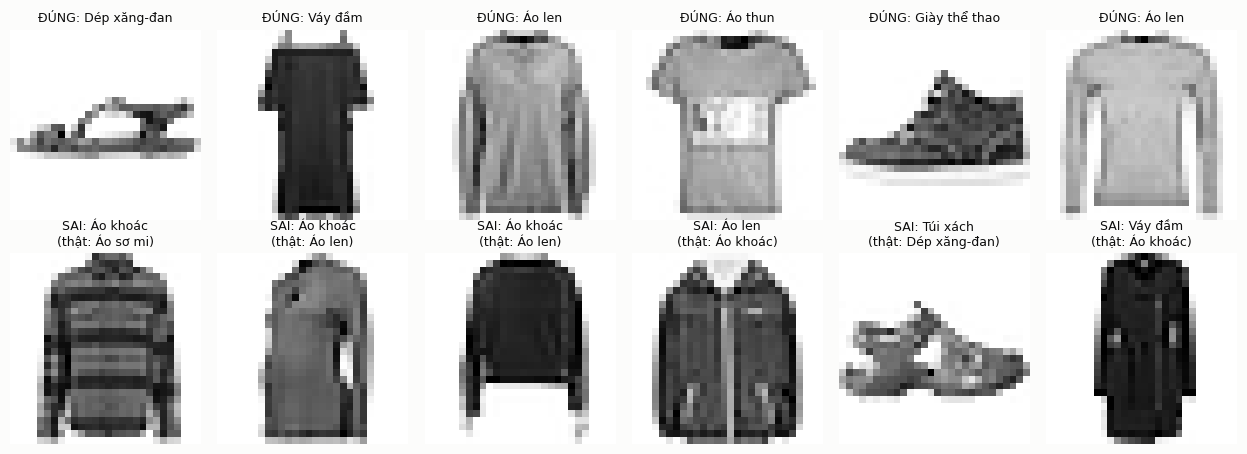

In [11]:
xem_du_doan(X_anh_val, y_anh_val)

### 💬 Câu hỏi cuối bài

Bấm đúp vào ô này để trả lời, rồi chia sẻ với cả lớp:
#câu trả lời:
#> 1. Val accuracy thấp nhất của tôi là 23.8%, với bộ tham số (0.1, 50,	15,	32,	0.0)
# 2. Lượt mà tôi học được nhiều nhất là lượt 1, vì từ đây tôi đã có thể cố định được số epoch vì lúc này train acc đã sắp chạm tới 100% rồi, chỉ cần thay đổi các tham số khác nữa thôi
# 3. Train accuracy và val accuracy của lượt tốt nhất cách nhau bao nhiêu? (0.135) Mô hình đang học chưa đủ, khớp tốt . Tôi nghĩ mô hình đang chưa khớp tốt rồi

> 1. Val accuracy cao nhất của tôi là 84.3%, với bộ tham số (0.001, 128,	50,	32,	0.0)
> 2. Lượt mà tôi học được nhiều nhất là lượt 2, vì từ đây tôi đã có thể cố định được số epoch vì lúc này train acc đã sắp chạm tới 100% rồi, chỉ cần thay đổi các tham số khác nữa thôi
> 3. Train accuracy và val accuracy của lượt tốt nhất cách nhau bao nhiêu? (0.135) Mô hình đang học chưa đủ, khớp tốt hay học quá khớp? Tôi nghĩ mô hình đang khớp tốt rồi

> ⚠️ **Một điều cần nhớ:** khi chọn tham số dựa vào validation nhiều lần, điểm validation sẽ hơi "lạc quan". Trong dự án thực tế, ta giữ thêm một **tập test** chỉ dùng đúng một lần ở cuối.

---
# 🎉 Tổng kết cả buổi

| Câu hỏi | Bài học |
|---|---|
| Máy học thế nào? | Dự đoán → đo sai số → cập nhật trọng số → lặp lại (Bài 1) |
| Vì sao cần hàm phi tuyến? | Để đường phân chia uốn cong được theo dữ liệu (Bài 1) |
| Làm sao biết đang học vẹt? | Vẽ cả train và validation, xem val có đi lên không (Bài 2) |
| Chữa học vẹt thế nào? | Dừng sớm, Dropout, thêm dữ liệu (Bài 2) |
| Tốc độ học quá lớn hay quá nhỏ? | Nhỏ thì chậm, lớn thì vượt đáy và dao động (Bài 3) |
| Kích thước lô để làm gì? | Đánh đổi giữa độ chắc của hướng đi và tốc độ tính toán (Bài 3) |